<a href="https://colab.research.google.com/github/charlotteanhtran-bit/datasciproject/blob/main/ML_stock_data_sci_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import yfinance as yf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn import metrics

import warnings
warnings.filterwarnings('ignore')

In [3]:
TICKER = 'NVDA'
df = yf.download(TICKER, period='10y', interval='1d', auto_adjust=False)

# yfinance can return multi-level columns; flatten them so 'Close' etc. are plain.
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.reset_index()  # turn the Date index into a normal column
print(df.head())
print("Shape:", df.shape)
print(df.describe())
print(df.info())

[*********************100%***********************]  1 of 1 completed

Price       Date  Adj Close    Close     High      Low     Open     Volume
0     2016-08-22   1.532686  1.56300  1.56525  1.54275  1.56125  244748000
1     2016-08-23   1.545088  1.57275  1.58300  1.56825  1.57600  339764000
2     2016-08-24   1.521264  1.54850  1.57900  1.54125  1.57825  298448000
3     2016-08-25   1.511195  1.53825  1.54975  1.51900  1.54900  406032000
4     2016-08-26   1.523475  1.55075  1.55950  1.53000  1.54225  300024000
Shape: (2514, 7)
Price                           Date    Adj Close        Close         High  \
count                           2514  2514.000000  2514.000000  2514.000000   
mean   2021-08-19 21:11:35.942720768    48.532589    48.620219    49.421206   
min              2016-08-22 00:00:00     1.461829     1.488000     1.515000   
25%              2019-02-21 06:00:00     5.318943     5.376188     5.463375   
50%              2021-08-18 12:00:00    15.304520    15.349750    15.553500   
75%              2024-02-19 00:00:00    72.517851    72.646

In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn import metrics
import warnings
warnings.filterwarnings('ignore')

TICKER = 'NVDA'
raw = yf.download(TICKER, period='10y', interval='1d', auto_adjust=False)
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)
raw = raw.reset_index().dropna().reset_index(drop=True)
print("Du lieu:", raw.shape, "| tu", raw['Date'].min().date(),
      "den", raw['Date'].max().date())

factor = raw['Adj Close'] / raw['Close']
raw['Adj Open'] = raw['Open'] * factor
raw['Adj High'] = raw['High'] * factor
raw['Adj Low'] = raw['Low'] * factor
print(f"He so dieu chinh: min={factor.min():.5f}  max={factor.max():.5f}  (1.0 = khong doi)\n")


def build_and_score(df, o, h, l, c, label):
    d = df.copy()
    d['open-close'] = d[o] - d[c]
    d['low-high'] = d[l] - d[h]
    d['is_quarter_end'] = np.where(d['Date'].dt.month % 3 == 0, 1, 0)
    d['target'] = np.where(d[c].shift(-1) > d[c], 1, 0)
    d = d.dropna().reset_index(drop=True)

    X = StandardScaler().fit_transform(
        d[['open-close', 'low-high', 'is_quarter_end']])
    y = d['target']
    Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.1, random_state=2022)

    print(f"=== {label}  (cot gia = '{c}') ===")
    print(f"   ty le target 1 (ngay tang): {y.mean():.3f}")
    for m in [LogisticRegression(),
              SVC(kernel='poly', probability=True),
              XGBClassifier()]:
        m.fit(Xtr, ytr)
        tr = metrics.roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1])
        va = metrics.roc_auc_score(yva, m.predict_proba(Xva)[:, 1])
        print(f"   {type(m).__name__:20s} train AUC {tr:.3f} | valid AUC {va:.3f}")
    print()


build_and_score(raw, 'Open', 'High', 'Low', 'Close',
                'PHIEN BAN A - gia tho (tutorial)')
build_and_score(raw, 'Adj Open', 'Adj High', 'Adj Low', 'Adj Close',
                'PHIEN BAN B - gia da dieu chinh')

[*********************100%***********************]  1 of 1 completed


Du lieu: (2514, 7) | tu 2016-08-22 den 2026-08-21
He so dieu chinh: min=0.98060  max=1.00000  (1.0 = khong doi)

=== PHIEN BAN A - gia tho (tutorial)  (cot gia = 'Close') ===
   ty le target 1 (ngay tang): 0.539
   LogisticRegression   train AUC 0.524 | valid AUC 0.507
   SVC                  train AUC 0.501 | valid AUC 0.505
   XGBClassifier        train AUC 0.929 | valid AUC 0.454

=== PHIEN BAN B - gia da dieu chinh  (cot gia = 'Adj Close') ===
   ty le target 1 (ngay tang): 0.539
   LogisticRegression   train AUC 0.524 | valid AUC 0.509
   SVC                  train AUC 0.501 | valid AUC 0.501
   XGBClassifier        train AUC 0.925 | valid AUC 0.489



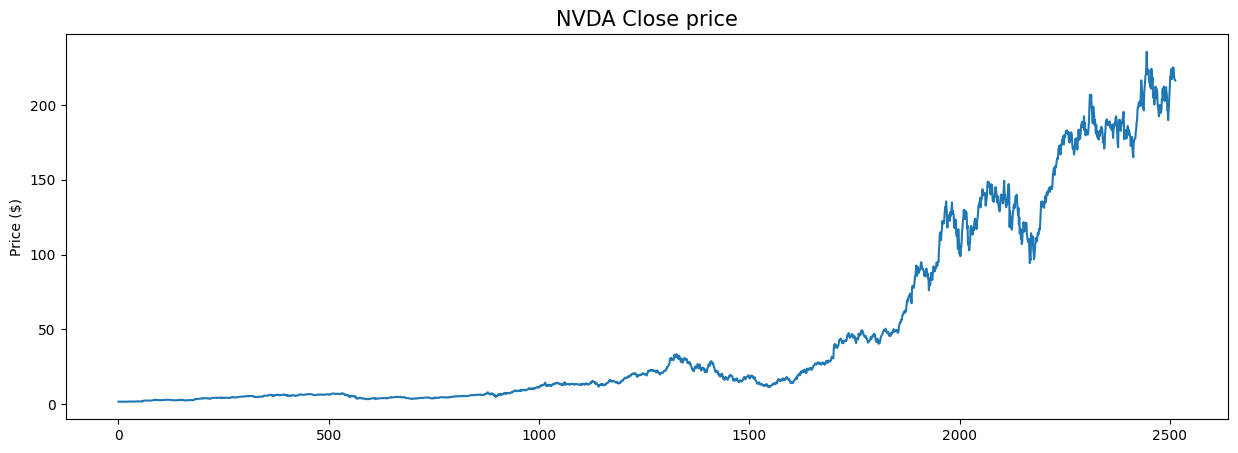

So ngay Close == Adj Close: 55 / 2514
Price
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64


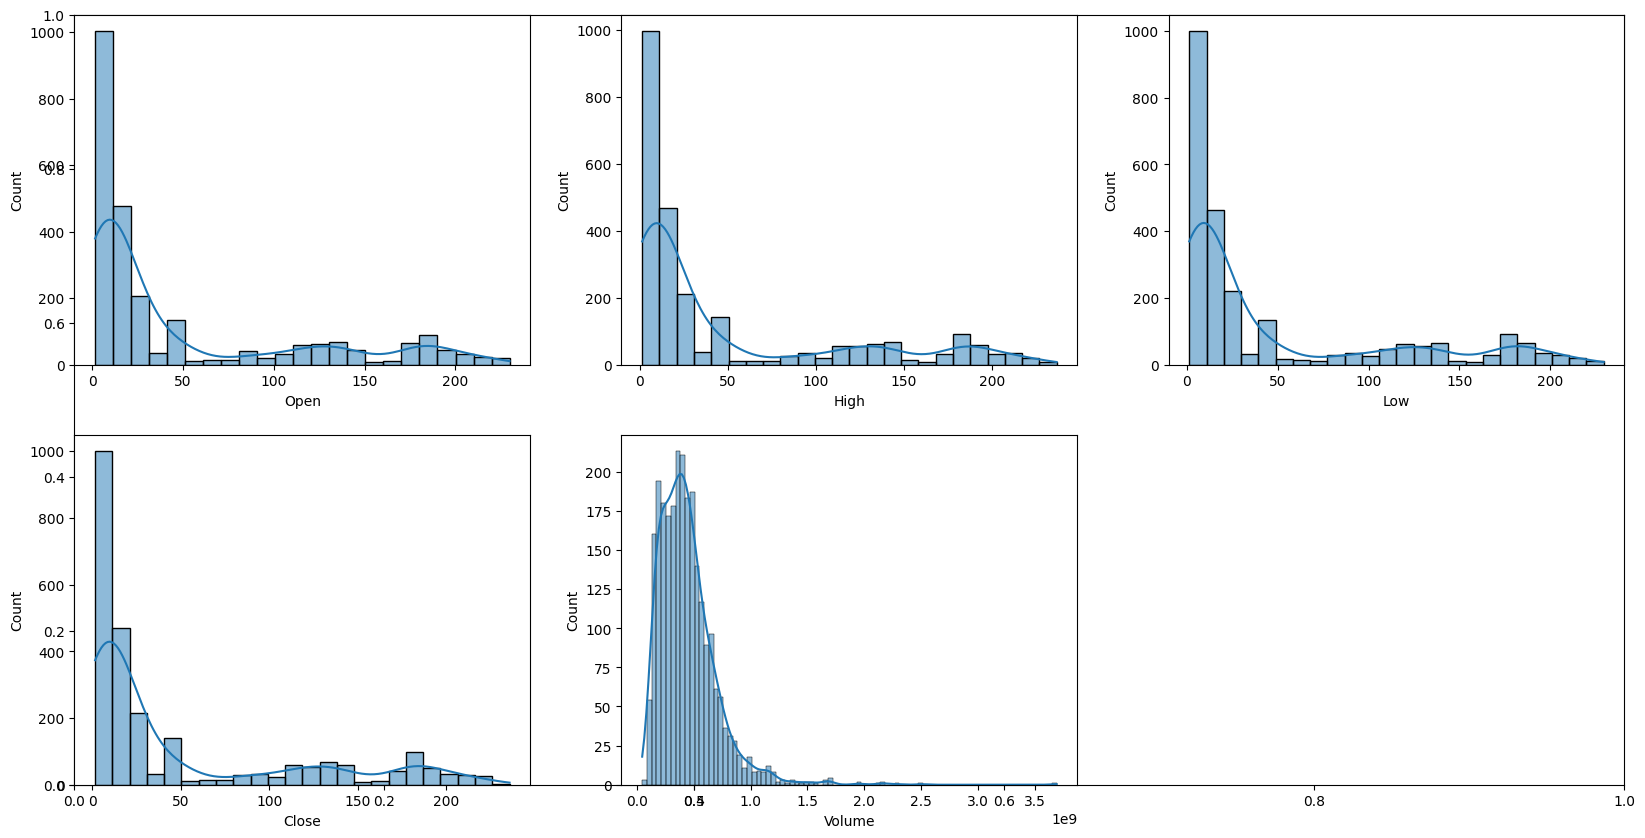

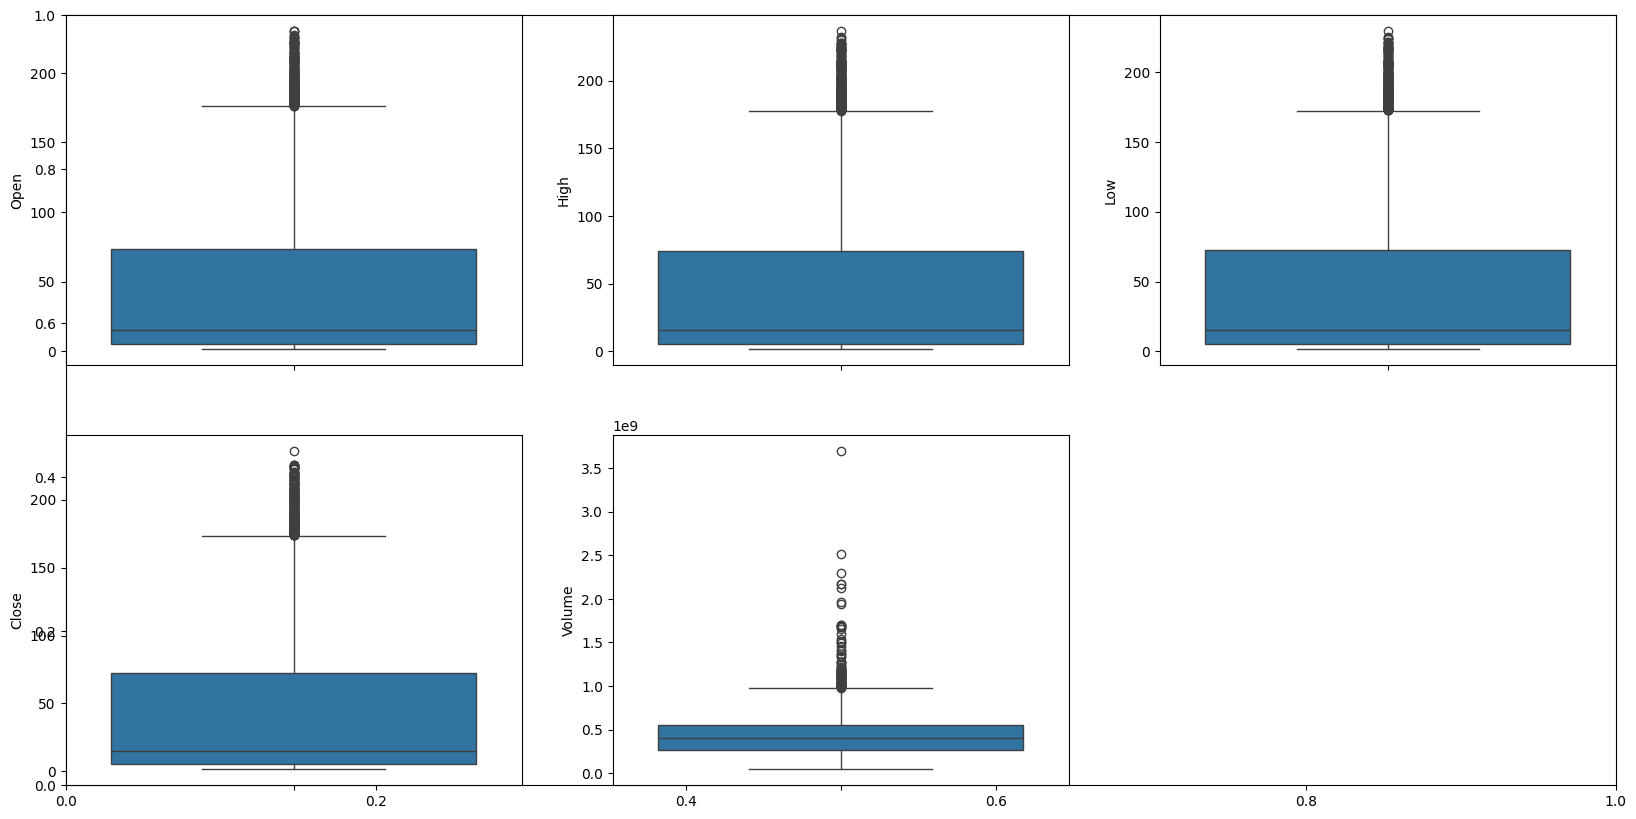

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Đã lưu: ['nvda_01_close_lineplot.png', 'nvda_02_distributions.png', 'nvda_03_boxplots.png']


In [5]:

import os, shutil
from google.colab import files

os.makedirs('charts', exist_ok=True)
df = df.dropna().reset_index(drop=True)


plt.figure(figsize=(15,5))
plt.plot(df['Close'])
plt.title('NVDA Close price', fontsize=15)
plt.ylabel('Price ($)')
plt.savefig('charts/nvda_01_close_lineplot.png', dpi=150, bbox_inches='tight')
plt.show()


print("So ngay Close == Adj Close:", df[df['Close'] == df['Adj Close']].shape[0], "/", len(df))
print(df.isnull().sum())


features = ['Open', 'High', 'Low', 'Close', 'Volume']
plt.subplots(figsize=(20,10))
for i, col in enumerate(features):
    plt.subplot(2,3,i+1)
    sb.histplot(df[col], kde=True)
plt.savefig('charts/nvda_02_distributions.png', dpi=150, bbox_inches='tight')
plt.show()


plt.subplots(figsize=(20,10))
for i, col in enumerate(features):
    plt.subplot(2,3,i+1)
    sb.boxplot(df[col])
plt.savefig('charts/nvda_03_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()

shutil.make_archive('nvda_eda_charts', 'zip', 'charts')
files.download('nvda_eda_charts.zip')
print("Đã lưu:", os.listdir('charts'))

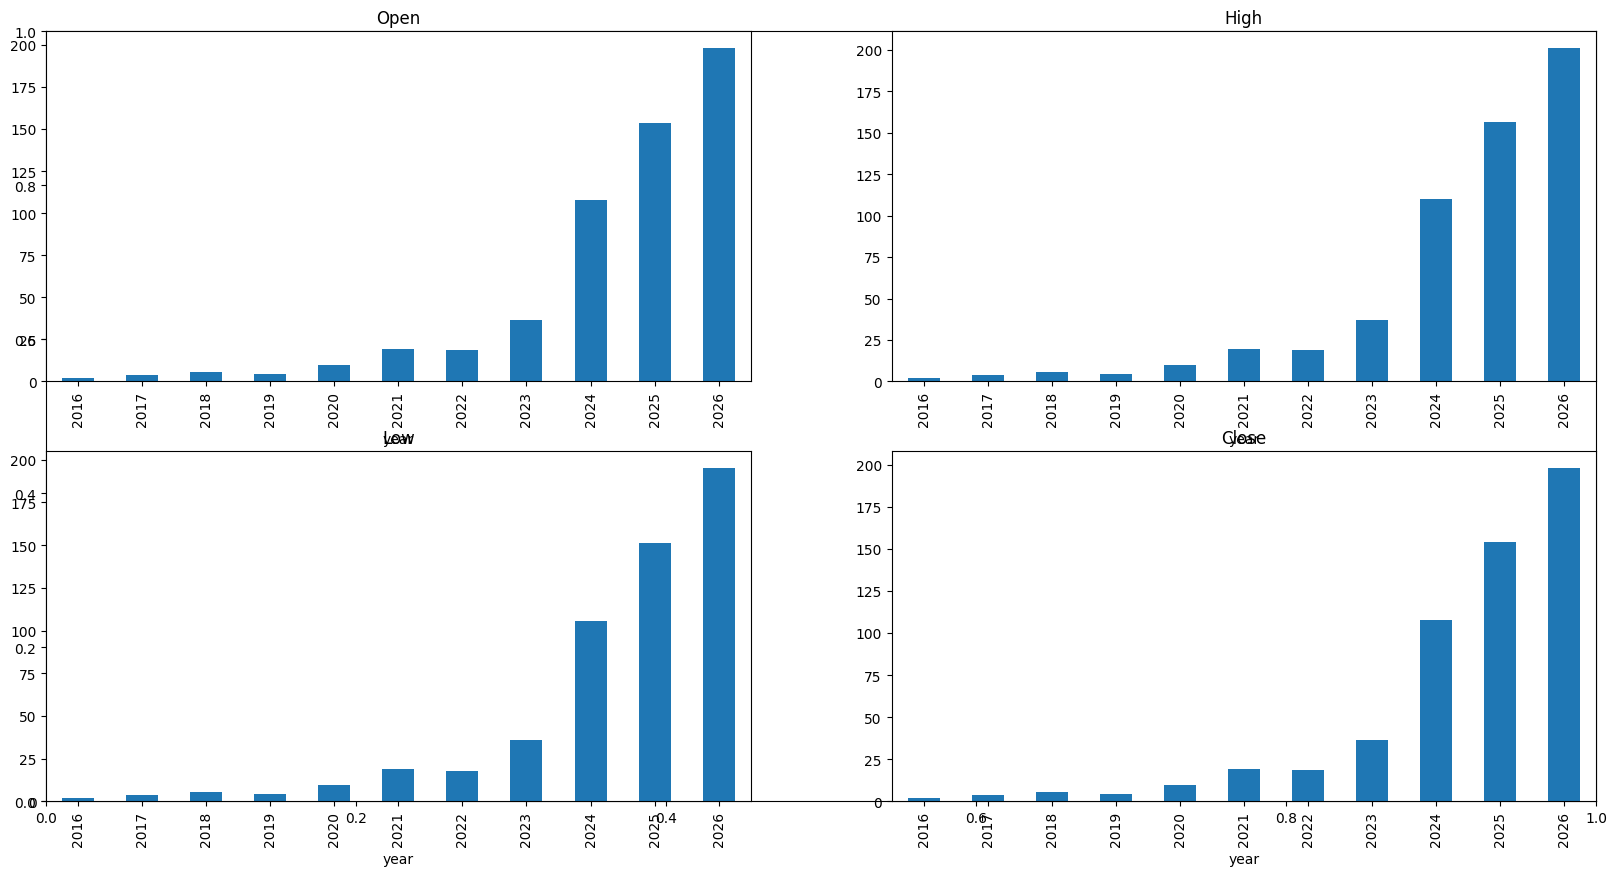

Price           Adj Close      Close       High        Low       Open  \
is_quarter_end                                                          
0               49.411956  49.501023  50.327477  48.605231  49.516605   
1               46.783265  46.868036  47.618362  46.073693  46.874498   

Price                 Volume        day     month         year  
is_quarter_end                                                  
0               4.390889e+08  15.759115  6.098027  2021.196653  
1               4.534364e+08  15.753864  7.437574  2021.004756  


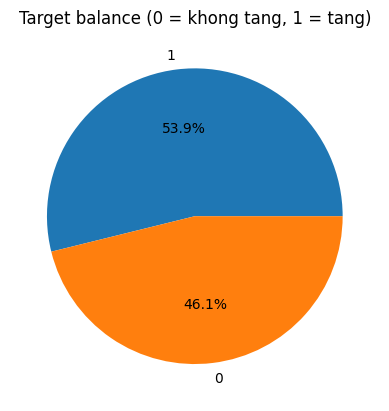

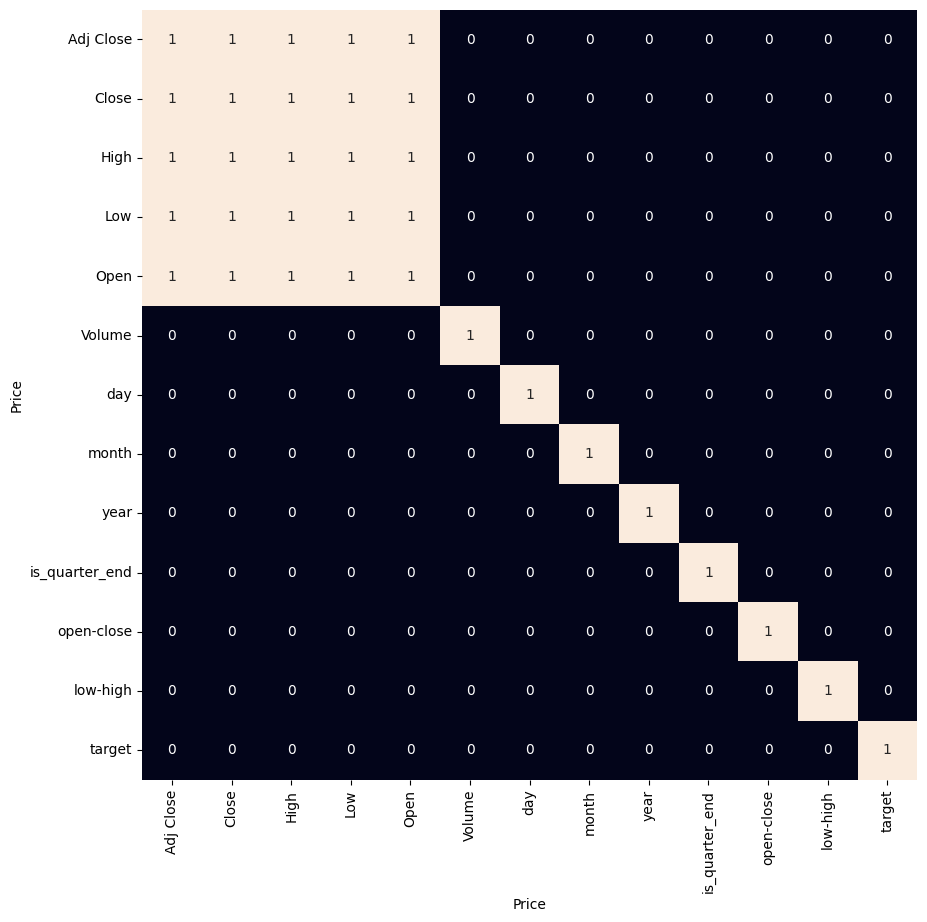

In [6]:

import os; os.makedirs('charts', exist_ok=True)


df['day']   = df['Date'].dt.day
df['month'] = df['Date'].dt.month
df['year']  = df['Date'].dt.year

df['is_quarter_end'] = np.where(df['month'] % 3 == 0, 1, 0)


data_grouped = df.drop('Date', axis=1).groupby('year').mean(numeric_only=True)
plt.subplots(figsize=(20,10))
for i, col in enumerate(['Open', 'High', 'Low', 'Close']):
    plt.subplot(2,2,i+1); data_grouped[col].plot.bar(); plt.title(col)
plt.savefig('charts/nvda_04_yearly_bars.png', dpi=150, bbox_inches='tight')
plt.show()

print(df.drop('Date', axis=1).groupby('is_quarter_end').mean(numeric_only=True))


df['open-close'] = df['Open'] - df['Close']
df['low-high']   = df['Low']  - df['High']
df['target']     = np.where(df['Close'].shift(-1) > df['Close'], 1, 0)


vc = df['target'].value_counts()
plt.pie(vc.values, labels=vc.index, autopct='%1.1f%%')
plt.title('Target balance (0 = khong tang, 1 = tang)')
plt.savefig('charts/nvda_05_target_pie.png', dpi=150, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10,10))
sb.heatmap(df.drop('Date', axis=1).corr(numeric_only=True) > 0.9, annot=True, cbar=False)
plt.savefig('charts/nvda_06_corr_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
print(df[['Open','Close','open-close','Low','High','low-high']].head())

Price     Open    Close  open-close      Low     High  low-high
0      1.56125  1.56300    -0.00175  1.54275  1.56525  -0.02250
1      1.57600  1.57275     0.00325  1.56825  1.58300  -0.01475
2      1.57825  1.54850     0.02975  1.54125  1.57900  -0.03775
3      1.54900  1.53825     0.01075  1.51900  1.54975  -0.03075
4      1.54225  1.55075    -0.00850  1.53000  1.55950  -0.02950


In [8]:
df = df.dropna().reset_index(drop=True)
feat_cols = ['open-close', 'low-high', 'is_quarter_end']

split = int(len(df) * 0.9)
train, valid = df.iloc[:split], df.iloc[split:]


scaler = StandardScaler()
X_tr = scaler.fit_transform(train[feat_cols])     # fit = học mean/std (chỉ train)
X_va = scaler.transform(valid[feat_cols])
y_tr, y_va = train['target'], valid['target']
print(X_tr.shape, X_va.shape)

(2262, 3) (252, 3)


In [10]:
! git --version

git version 2.34.1
